# FastPath on markets: who will move together next?

Prices are turned into **events** (big move, beat or lag the market, volume spike, FOMC day, earnings)
and events that happen together are joined through shared **Moments** ("day d, these assets beat the
market by ≥ 1σ"). FastPath embeds each asset's recent event path, as of a date, into one vector.

The point of the demo: FastPath does not just embed each asset's own history, it uses the **connections**
between assets. Run on the event attributes alone it is a weak predictor; fed the Moment graph instead,
the same algorithm gets about 25-30% better and beats the original Pearson demo, without ever computing
a correlation (sections 6-7, on the 99 assets and on the S&P 500).

The test is out-of-sample: as of each month-end, pick every asset's 10 nearest neighbours, then measure
how those pairs actually co-moved over the **next 60 trading days**. The baselines are trailing Pearson
(the original demo), sector membership and the raw Moment overlap.

Prerequisites: `scripts/01..04` run, `.env` filled (see `.env.example`).

## 1. Connect to AuraDB and start a Graph Analytics session

In [1]:
import os, sys, time, json
from pathlib import Path
import certifi
import numpy as np
import pandas as pd
from IPython.display import display
from dotenv import load_dotenv, find_dotenv
from neo4j import GraphDatabase
from graphdatascience.session import GdsSessions, AuraAPICredentials, DbmsConnectionInfo, AlgorithmCategory

os.environ.setdefault("SSL_CERT_FILE", certifi.where())
load_dotenv(find_dotenv(usecwd=True))
ROOT = Path.cwd() if (Path.cwd() / "config.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import config as C, fp, scoring as S
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 80)

URI, USER, PASSWORD = os.environ["NEO4J_URI"], os.environ["NEO4J_USERNAME"], os.environ["NEO4J_PASSWORD"]
DATABASE = os.environ.get("NEO4J_DATABASE", "neo4j")
SESSION_NAME = os.environ.get("FASTPATH_SESSION_NAME", "fastpath-finance-demo")

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
driver.verify_connectivity()
q = lambda cypher, **p: pd.DataFrame([r.data() for r in driver.execute_query(cypher, database_=DATABASE, **p).records])

c = q("""RETURN COUNT { (:Asset) } AS assets, COUNT { (:Snapshot) } AS snapshots,
                COUNT { (:MarketEvent) } AS events, COUNT { (:Moment) } AS moments,
                COUNT { ()-[:NEXT]->() } AS next, COUNT { ()-[:IN_MOMENT]->() } AS inMoment""").iloc[0]
display(c.to_frame("count").T)

sessions = GdsSessions(api_credentials=AuraAPICredentials(
    os.environ.get("CLIENT_ID") or os.environ["AURA-API-CLIENT-ID"],
    os.environ.get("CLIENT_SECRET") or os.environ["AURA-API-CLIENT-SECRET"],
    os.environ.get("PROJECT_ID") or os.environ.get("AURA_PROJECTID")))
# Session size drives CPU count, and FastPath runs once per month-end, so bigger = faster.
# Set FASTPATH_SESSION_MEMORY in .env (e.g. 32GB) to override the estimate.
n_assets = int(c["assets"])
memory = os.environ.get("FASTPATH_SESSION_MEMORY") or sessions.estimate(
    node_count=n_assets * 140 + 600, relationship_count=n_assets * 170,
    algorithm_categories=[AlgorithmCategory.NODE_EMBEDDING, AlgorithmCategory.COMMUNITY_DETECTION],
    node_label_count=3, node_property_count=9, relationship_property_count=0)
SESSION_NAME = f"{SESSION_NAME}-{os.environ.get('FASTPATH_SESSION_MEMORY', 'auto').lower()}"  # one session per size
# a session deleted or expired behind a running kernel makes every call fail with
# "Remote job was aborted by the runtime": set RESET_SESSION = True once to start clean
RESET_SESSION = False
if RESET_SESSION:
    sessions.delete(session_name=SESSION_NAME)
t0 = time.time()
gds = sessions.get_or_create(session_name=SESSION_NAME, memory=memory, ttl=pd.Timedelta(hours=3).to_pytimedelta(),
                             db_connection=DbmsConnectionInfo(uri=URI, username=USER, password=PASSWORD,
                                                              aura_instance_id=os.environ.get("AURA_ID") or os.environ.get("AURA_INSTANCEID")))
print(f"GDS session '{SESSION_NAME}' ready ({memory}) in {time.time() - t0:.0f}s")

,assets,snapshots,events,moments,next,inMoment
count,99,1683,45639,915,45540,11208


GDS session 'fastpath-finance-demo-16gb' ready (16GB) in 6s


## 2. What the graph looks like

One asset's path through the April 2025 tariff week, and the Moments it shared with others.
In Explore, run `cypher/explore.cypher` to show the same thing visually.

In [2]:
TICKER, FROM, TO = "NVDA", "2025-04-01", "2025-04-11"
display(q("""
MATCH (e:MarketEvent {ticker: $t}) WHERE $from <= e.date <= $to
OPTIONAL MATCH (e)-[:IN_MOMENT]->(m:Moment)
RETURN e.date AS date, round(e.ret * 100, 2) AS `ret %`, e.moveBucket AS move, e.excessBucket AS vsMarket,
       e.volBucket AS volume, e.dayType AS dayType, m.momentId AS moment, m.size AS assetsInMoment
ORDER BY date""", t=TICKER, **{"from": FROM, "to": TO}))

display(q("""
MATCH (m:Moment) WHERE $from <= m.date <= $to
RETURN m.date AS date, m.direction AS direction, m.size AS assets ORDER BY assets DESC LIMIT 8""",
          **{"from": FROM, "to": TO}))

,date,ret %,move,vsMarket,volume,dayType,moment,assetsInMoment
0,2025-04-01,1.62,2,2,1,0,NaN,NaN
1,2025-04-02,0.24,2,2,1,0,NaN,NaN
2,2025-04-03,-8.13,1,2,1,2,NaN,NaN
3,2025-04-04,-7.64,1,2,3,2,NaN,NaN
4,2025-04-07,3.47,2,2,3,0,NaN,NaN
5,2025-04-08,-1.38,2,2,2,0,NaN,NaN
6,2025-04-09,17.16,4,4,3,2,2025-04-09|up,33.0
7,2025-04-10,-6.10,1,2,2,2,NaN,NaN
8,2025-04-11,3.08,2,2,1,0,NaN,NaN


,date,direction,assets
0,2025-04-03,down,46
1,2025-04-09,down,42
2,2025-04-03,up,40
3,2025-04-09,up,33
4,2025-04-10,up,31
5,2025-04-10,down,28
6,2025-04-04,up,26
7,2025-04-04,down,25


## 3. The bar to beat

Before running anything, score the obvious methods. `pearson_30d` is the original demo,
`co_moment` is the Moment overlap alone (no return values at all), `oracle` is the ceiling.

In [3]:
ctx = S.Context()
baselines = S.evaluate([S.pearson(30), S.pearson(120), S.same_sector, S.co_moment], ctx)
display(baselines)

,dates,fwd_corr@10,fwd_corr@1,hit@10,hedge_err
method,,,,,
oracle,13,0.601,0.728,1.000,0.000
pearson_120d,13,0.512,0.631,0.529,0.097
co_moment,13,0.495,0.613,0.499,0.115
pearson_30d,13,0.471,0.579,0.433,0.149
same_sector,13,0.458,0.570,0.408,0.158
random,13,0.253,0.252,0.102,0.476


## 4. FastPath as of one date, live

Project the graph *as of* `DEMO_DATE` (only the 180 days before it), then embed every asset.
FastPath walks each asset's event chain in time (`FIRST_EVENT`, `NEXT`, 26 weekly time anchors) and
reads the **context** each event is connected to: the Moments it shared with other assets.
The per-event attributes (move / volume buckets, z-scores) are switched off here: section 6 shows
they drown the connected signal.

In [4]:
import threading
DEMO_DATE = "2025-03-31"          # the last month-end before the tariff shock
# FastPath setting used by sections 4, 6 and 11. Change it to try a variant:
# each setting gets its own cache file in results/, and section 6b compares them all.
FP_PARAMS = dict(dim=512, decay_rate=0.0, seed=42, categorical=[], features=False)   # connected: graph context only
EVENTS_ONLY = dict(dim=512, decay_rate=0.0, seed=42)   # the ablation: per-event attributes, no context (section 6)

t0 = time.perf_counter()
G = fp.project_as_of(gds, DEMO_DATE, with_moments=True, name="fp_demo")
print(f"projected '{G.name()}': {G.node_count():,} nodes / {G.relationship_count():,} relationships "
      f"in {time.perf_counter() - t0:.1f}s")

done = threading.Event()
def stopwatch(t0):
    while not done.wait(0.1):
        print(f"\r⏱  FastPath running ... {time.perf_counter() - t0:5.1f} s", end="", flush=True)
t0 = time.perf_counter(); th = threading.Thread(target=stopwatch, args=(t0,), daemon=True); th.start()
try:
    r = fp.run_fastpath(gds, G, with_moments=True, **FP_PARAMS)
finally:
    done.set(); th.join()
print(f"\r{r.node_properties_written} embeddings x {FP_PARAMS['dim']} dims   compute {r.compute_millis / 1000:.2f}s   "
      f"wall {time.perf_counter() - t0:.2f}s")
emb_demo = fp.stream_embeddings(gds, G)

projected 'fp_demo': 12,419 nodes / 15,117 relationships in 1.2s
⏱  FastPath running ...   0.1 s

⏱  FastPath running ...   0.2 s

⏱  FastPath running ...   0.3 s

⏱  FastPath running ...   0.4 s

⏱  FastPath running ...   0.6 s

⏱  FastPath running ...   0.7 s

... (187 outputs left out)

⏱  FastPath running ...  21.0 s

FASTPATH: 100%|##########| 100.0/100 [00:00<?, ?%/s]

⏱  FastPath running ...  21.1 s

99 embeddings x 512 dims   compute 7.26s   wall 21.08s


## 5. Neighbours vs. what happened next

FastPath's nearest neighbours as of `DEMO_DATE` next to trailing 30-day Pearson, each with the
correlation realised over the following 60 trading days (unseen by both).

In [5]:
FOCUS = "NVDA"
fwd = ctx.future(DEMO_DATE, C.FORWARD_DAYS).corr()[FOCUS]
fpn = fp.neighbours(emb_demo, DEMO_DATE, FOCUS)
p30 = ctx.past(DEMO_DATE, 30).corr()[FOCUS].drop(FOCUS).nlargest(10)
side = pd.DataFrame({
    "FastPath": fpn.index, "fwd corr ": fwd[fpn.index].round(2).to_numpy(),
    "Pearson 30d": p30.index, "fwd corr": fwd[p30.index].round(2).to_numpy()})
display(side)
print(f"mean forward corr  FastPath {fwd[fpn.index].mean():.3f}   Pearson 30d {fwd[p30.index].mean():.3f}")

,FastPath,fwd corr,Pearson 30d,fwd corr
0,ORCL,0.66,AMAT,0.88
1,ISRG,0.80,KLAC,0.87
2,MU,0.84,AVGO,0.86
3,AVGO,0.86,LRCX,0.90
4,BSX,0.65,MU,0.84
5,META,0.86,AMD,0.87
6,MSFT,0.80,AMZN,0.85
7,AMD,0.87,WMB,0.53
8,GOOGL,0.69,QCOM,0.77
9,WMB,0.53,MSFT,0.80


mean forward corr  FastPath 0.757   Pearson 30d 0.818


## 6. Every month-end: connected vs. event attributes only

Same run for every snapshot date, twice:
- **connected**: FastPath reads the Moments each event belongs to, i.e. which other assets moved with it that day
- **events only**: FastPath reads each event's own attributes (move / vs-market / volume buckets, FOMC and
  shock days, earnings, 5 z-scores) and no context at all

Same algorithm, same time windows: the difference is what the graph adds.

In [6]:
dates = sorted(q("MATCH (s:Snapshot) RETURN DISTINCT s.date AS d")["d"])
# cached + resumable: dates already in results/*.csv are loaded, not recomputed.
# Run this once before the demo; on stage it only reads the files.
# To recompute the same setting from scratch: (C.RESULTS / fp.cache_name(FP_PARAMS)).unlink()
emb = fp.embed_dates(gds, dates, with_moments=True, cache=fp.cache_name(FP_PARAMS), **FP_PARAMS)
emb_events = fp.embed_dates(gds, dates, with_moments=False, cache=fp.cache_name(EVENTS_ONLY, False), **EVENTS_ONLY)
print(f"{len(emb):,} snapshot embeddings over {emb['date'].nunique()} dates")


17 dates cached, 0 to compute
0 dates cached, 17 to compute


FASTPATH [elapsed: 00:00 ]

FASTPATH:   0%|          | 0.0/100 [00:00<?, ?%/s]

FASTPATH:   0%|          | 0.0/100 [00:00<?, ?%/s]

FASTPATH: 100%|##########| 100.0/100 [00:00<?, ?%/s]

[ 1/17] 2024-03-28   12,375 nodes    99 emb  project   1.0s  fastpath  16.6s  stream+drop   0.5s


... (63 outputs left out)

FASTPATH:   0%|          | 0.0/100 [00:00<?, ?%/s]

FASTPATH: 100%|##########| 100.0/100 [00:00<?, ?%/s]

[17/17] 2025-07-09   12,177 nodes    99 emb  project   0.8s  fastpath  16.4s  stream+drop   0.6s


1,683 snapshot embeddings over 17 dates


## 6b. Compare FastPath settings

Every setting already computed (one file per setting in `results/`), scored against the two
references to beat: trailing 120-day Pearson and the raw Moment overlap. Rehearsal only, not for stage.

In [7]:
variants = fp.load_variants()
print("settings found:", ", ".join(variants))
display(S.evaluate([S.pearson(120), S.co_moment]
                   + [S.embeddings(e, name) for name, e in variants.items()], ctx))


settings found: dim256_decay0.0_seed42, dim256_decay0.0_seed42_cat_nofeat, dim256_decay0.0_seed42_cat_nofeat_holders, dim256_decay0.0_seed42_cat_nofeat_smoothing_rate0.5_smoothing_window5, dim256_decay0.0_seed42_holders, dim256_decay0.0_seed42_nomoments, dim256_decay0.0_seed42_nomoments_holders, dim256_decay1.0_seed42_cat_nofeat, dim512_decay0.0_seed42_cat_nofeat, dim512_decay0.0_seed42_nomoments, dim64_decay0.0_seed42


,dates,fwd_corr@10,fwd_corr@1,hit@10,hedge_err
method,,,,,
oracle,13,0.601,0.728,1.000,0.000
pearson_120d,13,0.512,0.631,0.529,0.097
co_moment,13,0.495,0.613,0.499,0.115
dim512_decay0.0_seed42_cat_nofeat,13,0.488,0.607,0.484,0.121
dim256_decay0.0_seed42_cat_nofeat,13,0.481,0.598,0.472,0.130
dim256_decay0.0_seed42_cat_nofeat_smoothing_rate0.5_smoothing_window5,13,0.479,0.596,0.469,0.132
dim256_decay0.0_seed42_cat_nofeat_holders,13,0.405,0.513,0.340,0.215
dim256_decay0.0_seed42,13,0.399,0.542,0.335,0.186
dim512_decay0.0_seed42_nomoments,13,0.395,0.529,0.322,0.199


## 7. The reveal

Forward 60-day correlation of the top-10 picks, precision against the true forward top-10, and
how far the #1 pick is from the best possible partner. Watch the two FastPath rows.

,dates,fwd_corr@10,fwd_corr@1,hit@10,hedge_err
method,,,,,
oracle,13,0.601,0.728,1.000,0.000
pearson_120d,13,0.512,0.631,0.529,0.097
co_moment,13,0.495,0.613,0.499,0.115
fastpath (connected),13,0.488,0.607,0.484,0.121
pearson_30d,13,0.471,0.579,0.433,0.149
same_sector,13,0.458,0.570,0.408,0.158
fastpath_events_only,13,0.395,0.529,0.322,0.199
random,13,0.253,0.252,0.102,0.476


the graph adds +24% to FastPath, which ends +0.017 vs the original Pearson-30d demo


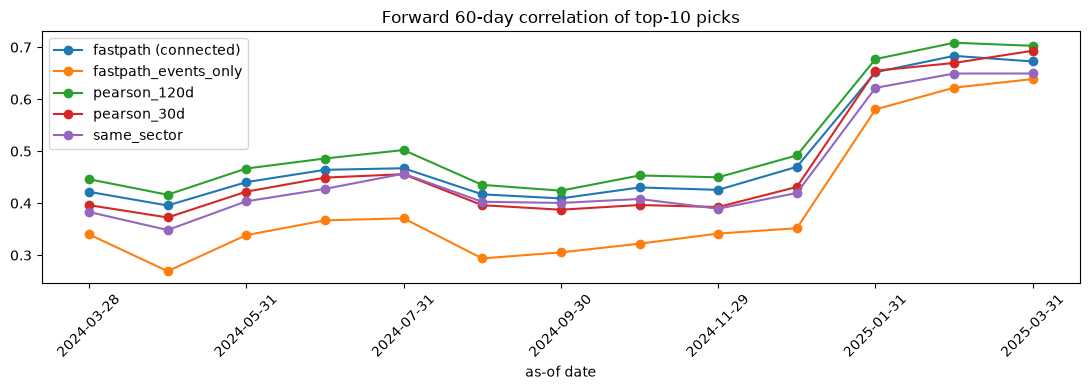

In [8]:
summary, per_date = S.evaluate(
    [S.pearson(30), S.pearson(120), S.same_sector, S.co_moment,
     S.embeddings(emb, "fastpath (connected)"), S.embeddings(emb_events, "fastpath_events_only")],
    ctx, per_date=True)
display(summary)
k = f"fwd_corr@{C.TOP_K}"
print(f"the graph adds {summary.loc['fastpath (connected)', k] / summary.loc['fastpath_events_only', k] - 1:+.0%} "
      f"to FastPath, which ends {summary.loc['fastpath (connected)', k] - summary.loc['pearson_30d', k]:+.3f} "
      f"vs the original Pearson-30d demo")

import matplotlib.pyplot as plt
ax = per_date.pivot(index="date", columns="method", values=k) \
    .filter(["fastpath (connected)", "fastpath_events_only", "pearson_120d", "pearson_30d", "same_sector"]) \
    .plot(figsize=(11, 4), marker="o", title=f"Forward {C.FORWARD_DAYS}-day correlation of top-{C.TOP_K} picks")
ax.set_xlabel("as-of date"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 7b. Same test on the S&P 500

498 assets, 36 scored month-ends (2023-08 to 2026-07), same settings. Computed offline: the S&P 500 is not
loaded in AuraDB, so each as-of graph is built from `data/sp500/built` and sent to the session with
`gds.graph.construct` (`FASTPATH_UNIVERSE=sp500`, `fp.embed_dates(..., construct=True)`).

In [9]:
sp = pd.read_csv(C.ROOT / "results" / "sp500" / "fastpath_ablation.csv", index_col="method")
display(sp)
print(f"S&P 500: the graph adds {sp.loc['fastpath (connected)', k] / sp.loc['fastpath_events_only', k] - 1:+.0%} "
      f"to FastPath, which ends {sp.loc['fastpath (connected)', k] - sp.loc['pearson_30d', k]:+.3f} vs Pearson 30d")

,dates,fwd_corr@10,fwd_corr@1,hit@10,hedge_err
method,,,,,
oracle,36,0.621,0.731,1.000,0.000
pearson_120d,36,0.470,0.588,0.299,0.143
co_moment,36,0.440,0.563,0.265,0.168
fastpath (connected),36,0.430,0.551,0.250,0.180
pearson_30d,36,0.415,0.519,0.225,0.212
same_sector,36,0.399,0.498,0.218,0.233
fastpath_events_only,36,0.329,0.425,0.138,0.306
random,36,0.200,0.202,0.020,0.529


S&P 500: the graph adds +31% to FastPath, which ends +0.015 vs Pearson 30d


## 8. Clusters as of `DEMO_DATE`, named after the fact

k-means on the embeddings only. Sector was never an input, so it is fair to use it to *name*
the clusters, together with the Moments most of their members shared.

In [ ]:
if any("cluster" in p for p in G.node_properties().values()):
    gds.graph.node_properties.drop(G, ["cluster"], fail_if_missing=False)
km = gds.kmeans.mutate(G, node_property="fastPathEmbedding", mutate_property="cluster", k=8,
                       node_labels=["Snapshot"], initial_sampler="KMEANS++", number_of_restarts=10,
                       max_iterations=50, random_seed=42, concurrency=1, compute_silhouette=True)
print(f"silhouette {km.average_silhouette:.3f}")
clusters = gds.graph.node_properties.stream(G, ["cluster"], node_labels=["Snapshot"], db_node_properties=["ticker"])
if "nodeProperty" in clusters.columns:
    clusters = clusters.rename(columns={"propertyValue": "cluster"})
clusters = clusters[["ticker", "cluster"]].astype({"cluster": int})

obs = fp.to_day(DEMO_DATE)
member_moments = q("""
MATCH (e:MarketEvent)-[:IN_MOMENT]->(m:Moment)
WHERE $obs - $lb < e.day <= $obs
RETURN e.ticker AS ticker, m.momentId AS momentId""", obs=obs, lb=C.LOOKBACK_DAYS)
assets = q("MATCH (a:Asset) RETURN a.ticker AS ticker, a.sector AS sector, a.subIndustry AS subIndustry")
display(fp.name_clusters(clusters, assets, member_moments))

## 9. Who changed neighbourhood across the shock?

Neighbour-set overlap between the end of February and the end of April 2025 (compares top-10
sets, so the two embedding runs do not need to share a coordinate system).

In [ ]:
display(fp.drift(emb, "2025-02-28", "2025-04-30").head(15))

## 10. Why are two assets neighbours?

The graph answers what a vector store cannot: the Moments the pair shared in the look-back window.

In [ ]:
A, B = FOCUS, fpn.index[0]
display(q("""
MATCH (a:MarketEvent {ticker: $a})-[:IN_MOMENT]->(m:Moment)<-[:IN_MOMENT]-(b:MarketEvent {ticker: $b})
WHERE $obs - $lb < m.day <= $obs
RETURN m.date AS date, m.direction AS together, m.size AS assetsInMoment,
       round(a.ret * 100, 2) AS `ret A %`, round(b.ret * 100, 2) AS `ret B %`
ORDER BY date DESC""", a=A, b=B, obs=obs, lb=C.LOOKBACK_DAYS))

## 11. Hedge / substitute finder with a vector index

Write the `DEMO_DATE` embeddings back to AuraDB and query them like any vector property.

In [ ]:
# the index has a fixed dimension: drop it first if you changed FP_PARAMS["dim"]
# driver.execute_query("DROP INDEX snapshot_fastpath IF EXISTS", database_=DATABASE)
gds.graph.node_properties.write(G, ["fastPathEmbedding"], node_labels=["Snapshot"])
driver.execute_query("""
CREATE VECTOR INDEX snapshot_fastpath IF NOT EXISTS FOR (s:Snapshot) ON s.fastPathEmbedding
OPTIONS { indexConfig: { `vector.dimensions`: $dim, `vector.similarity_function`: 'cosine' } }""",
                     dim=FP_PARAMS["dim"], database_=DATABASE)
driver.execute_query("CALL db.awaitIndexes(300)", database_=DATABASE)
display(q("""
MATCH (s:Snapshot {ticker: $t, date: $d})
CALL db.index.vector.queryNodes('snapshot_fastpath', 1000, s.fastPathEmbedding) YIELD node, score
WHERE node.date = $d AND node <> s
MATCH (a:Asset)-[:HAS_SNAPSHOT]->(node)
RETURN a.ticker AS ticker, a.name AS name, a.subIndustry AS subIndustry, round(score, 3) AS similarity
LIMIT 10""", t="JPM", d=DEMO_DATE))

## Clean up

In [ ]:
DELETE_SESSION = False   # True at the very end of the demo: stops billing
for info in gds.graph.list():
    gds.graph.drop(info.graph_name, fail_if_missing=False)
q("MATCH (s:Snapshot) WHERE s.fastPathEmbedding IS NOT NULL REMOVE s.fastPathEmbedding RETURN count(s) AS cleaned")
if DELETE_SESSION:
    gds.delete(); print("session deleted")